In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Load your renamed dataset file
df = pd.read_csv("../data/raw/influencers_raw.csv")

print("Dataset Sizing Matrix Grid Dimensions:", df.shape)
df.info()
print("\nMissing Values Count per Column:\n", df.isnull().sum())
df.describe()


Dataset Sizing Matrix Grid Dimensions: (1000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Name                  1000 non-null   str  
 1   Rank                  1000 non-null   int64
 2   Category              916 non-null    str  
 3   Followers             1000 non-null   str  
 4   Audience Country      986 non-null    str  
 5   Authentic Engagement  1000 non-null   str  
 6   Engagement Avg.       1000 non-null   str  
dtypes: int64(1), str(6)
memory usage: 105.2 KB

Missing Values Count per Column:
 Name                     0
Rank                     0
Category                84
Followers                0
Audience Country        14
Authentic Engagement     0
Engagement Avg.          0
dtype: int64


,Rank
count,1000.000000
mean,500.500000
std,288.819436
min,1.000000
25%,250.750000
50%,500.500000
75%,750.250000
max,1000.000000


In [10]:
# Clean and normalize columns to lowercase format with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_").str.replace(".", "", regex=False)

print("Duplicate Row Count Recorded:", df.duplicated().sum())
df = df.drop_duplicates()

# Dynamically resolve potential text format metric numbers (e.g. '1.2M' or '45.5K')
def convert_metric_string_to_numeric(val):
    if isinstance(val, str):
        val = val.upper().strip()
        if 'M' in val: return float(val.replace('M', '')) * 1000000
        if 'K' in val: return float(val.replace('K', '')) * 1000
    try:
        return float(val)
    except Exception:
        return np.nan

# Clean and transform the key metrics columns
target_cols = ['followers', 'engagement_avg']
for col in target_cols:
    if col in df.columns:
        df[col] = df[col].apply(convert_metric_string_to_numeric)

# Drop missing values and filter out zero counts
df = df.dropna(subset=['followers', 'engagement_avg'])
df = df[df['followers'] > 0]

print("Cleaned Dataset Matrix Dimensions:", df.shape)


Duplicate Row Count Recorded: 0
Cleaned Dataset Matrix Dimensions: (1000, 7)


In [11]:
# Business Metric Formula: Engagement Rate % = (Average Engagement / Followers) * 100
df['engagement_rate'] = (df['engagement_avg'] / df['followers']) * 100
df['engagement_rate'] = df['engagement_rate'].round(4)

# Segment accounts into standard tier levels
def assign_market_tier(follower_count):
    if follower_count < 10000: return "Nano"
    elif follower_count < 100000: return "Micro"
    elif follower_count < 500000: return "Mid"
    elif follower_count < 1000000: return "Macro"
    return "Mega"

df['tier'] = df['followers'].apply(assign_market_tier)

# Engineering Performance Scores (60% Engagement weight + 40% Reach weight)
df['er_rank'] = df['engagement_rate'].rank(pct=True)
df['reach_rank'] = df['followers'].rank(pct=True)
df['performance_score'] = (0.6 * df['er_rank'] + 0.4 * df['reach_rank']) * 100

# Save out the structural base table to processed data folders
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/influencers_clean.csv", index=False)

df[['name', 'followers', 'engagement_rate', 'tier', 'performance_score']].head()


,name,followers,engagement_rate,tier,performance_score
0,cristiano,462900000.0,1.4258,Mega,56.52
1,leomessi,347200000.0,1.3825,Mega,55.90
2,kendalljenner,247600000.0,1.9790,Mega,61.62
3,arianagrande,321400000.0,1.0579,Mega,52.26
4,zendaya,147000000.0,3.9456,Mega,71.96


In [12]:
top10 = df.nlargest(10, "engagement_rate")[
    ["name", "category", "followers", "engagement_rate"]
]
top10


,name,category,followers,engagement_rate
772,la_beaute_africaine,Photography,1600000.0,118.7500
674,sugaringcandy,NaN,2500000.0,56.0000
299,jy_piece,NaN,4800000.0,45.8333
843,josephquinn,NaN,2500000.0,44.0000
249,mina_sr_my,NaN,5600000.0,42.8571
101,yawnzzn,NaN,9600000.0,42.7083
193,thinkaboutzu,NaN,6600000.0,42.4242
282,_zyozyo,NaN,5500000.0,38.1818
726,everyone_woo,NaN,2900000.0,37.9310
512,dear.zia,Lifestyle,3700000.0,37.8378


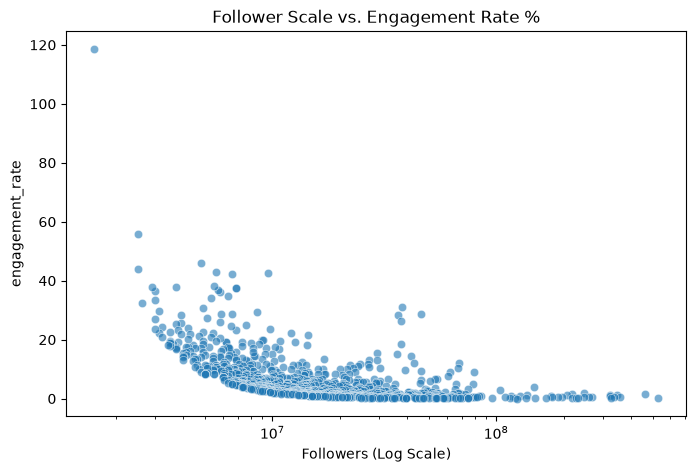


Mean Engagement Rate by Tier:
 tier
Mega    6.134911
Name: engagement_rate, dtype: float64

Follower-to-Engagement Correlation Vector: -0.2263888327449438


In [13]:
plt.style.use('default')
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="followers", y="engagement_rate", alpha=0.6)
plt.xscale("log")
plt.title("Follower Scale vs. Engagement Rate %")
plt.xlabel("Followers (Log Scale)")

plt.savefig("../images/followers_vs_engagement.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nMean Engagement Rate by Tier:\n", df.groupby("tier")["engagement_rate"].mean().sort_values(ascending=False))
print("\nFollower-to-Engagement Correlation Vector:", df["followers"].corr(df["engagement_rate"]))


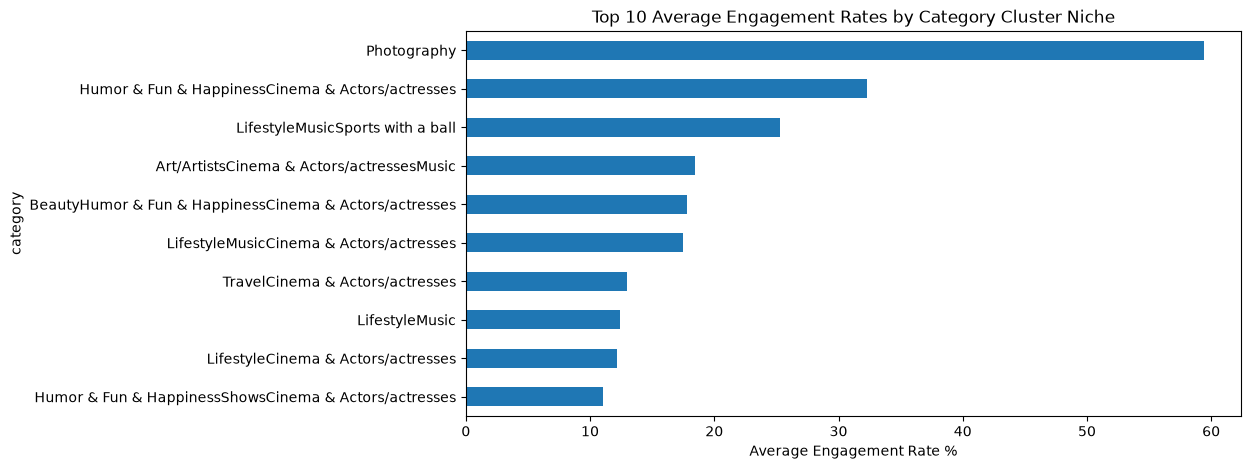

In [14]:
plt.figure(figsize=(10, 5))
df.groupby("category")["engagement_rate"].mean().sort_values().tail(10).plot(
    kind="barh", title="Top 10 Average Engagement Rates by Category Cluster Niche"
)
plt.xlabel("Average Engagement Rate %")
plt.savefig("../images/engagement_by_category.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(df[["followers", "engagement_avg", "engagement_rate", "performance_score"]].corr(),
            annot=True, cmap="Blues", fmt=".2f")
plt.title("Metric Correlation Heatmap Grid Matrix")
plt.savefig("../images/correlation.png", dpi=150, bbox_inches="tight")
plt.close()

# Filter candidates matching top 25% performance yields
shortlist = df[(df["engagement_rate"] > df["engagement_rate"].quantile(0.75)) &
               (df["followers"] > 10000)].nlargest(20, "performance_score")

shortlist.to_csv("../data/processed/top_influencers_shortlist.csv", index=False)
shortlist[["name", "category", "followers", "engagement_rate", "performance_score"]]
